# Experiment 04: Anomalies

Card: [exp04_anomalies.md](../../experiments/exp04_anomalies.md)

In [ ]:
import os
import sys

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "../../..")  # the ashrae package lives in the homework folder
sys.path.insert(0, "../..")  # the section's src package
from ashrae.config import FOLDS, METERS
from ashrae.data import read_processed
from ashrae.metrics import rmsle
from src.raw_data import anomaly_flags, clean_weather, read_weather

SMOKE = os.environ.get("SMOKE") == "1"
WEATHER = ["air_temperature", "dew_temperature", "sea_level_pressure", "wind_speed", "wind_direction"]
FEATURES = ["meter", "primary_use", "square_feet", "year_built", *WEATHER, "hour", "dayofweek"]
if SMOKE:
    BUILDINGS = [*range(10), 1303]  # includes both plotted examples
    FOLD_NAMES = list(FOLDS)[:2]
    N_TRAIN, N_VAL = 20_000, 5_000
    N_TREES = 10
else:
    BUILDINGS = None  # all
    FOLD_NAMES = list(FOLDS)
    N_TRAIN, N_VAL = 2_000_000, 500_000  # rows sampled per fold, as in the model notebooks
    N_TREES = 500

pd.set_option("display.float_format", "{:,.3f}".format)

## Anomaly rules

In [ ]:
data = read_processed()
if BUILDINGS:
    data = data[data.building_id.isin(BUILDINGS)]
data = data.sort_values(["building_id", "meter", "timestamp"]).reset_index(drop=True)
flags = anomaly_flags(data)
data[["zero_electricity", "off_when_needed"]] = flags[["zero_electricity", "off_when_needed"]]
zero_run_hours = flags.zero_run_hours
data.groupby(data.meter.map(METERS))[["zero_electricity", "off_when_needed"]].mean().mul(100).round(1).rename_axis(
    "% of rows"
)

,zero_electricity,off_when_needed
% of rows,,
chilledwater,0.000,1.000
electricity,4.400,0.000
hotwater,0.000,0.400
steam,0.000,0.800


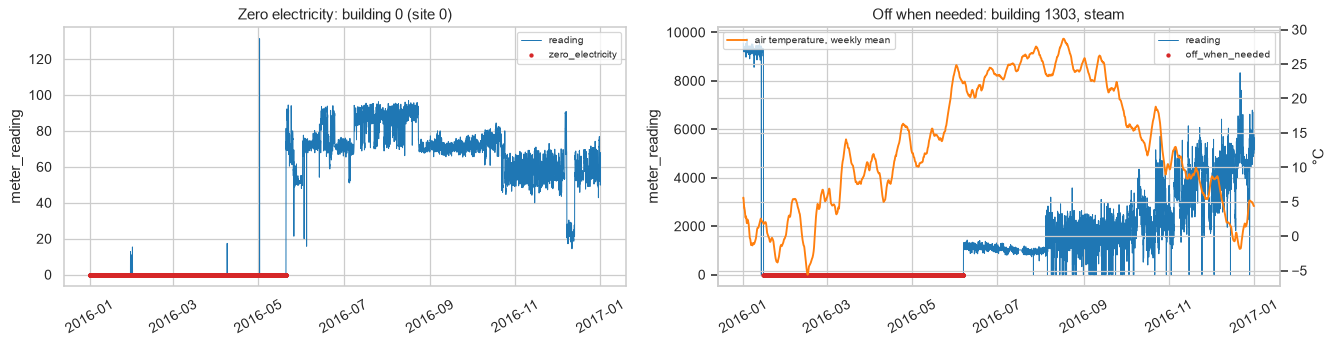

In [ ]:
def plot_example(ax, building_id, meter, flag, title):
    s = data[(data.building_id == building_id) & (data.meter == meter)]
    ax.plot(s.timestamp, s.meter_reading, lw=0.8, color="tab:blue", label="reading")
    ax.scatter(s.timestamp[s[flag]], s.meter_reading[s[flag]], s=6, color="tab:red", label=flag, zorder=3)
    ax.set(title=title, ylabel="meter_reading")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(loc="upper right", fontsize=8)
    return s


fig, axes = plt.subplots(1, 2, figsize=(15, 4))
plot_example(axes[0], 0, 0, "zero_electricity", "Zero electricity: building 0 (site 0)")
steam = plot_example(axes[1], 1303, 2, "off_when_needed", "Off when needed: building 1303, steam")
temp_ax = axes[1].twinx()
temp_ax.plot(steam.timestamp, steam.air_temperature.rolling(24 * 7, min_periods=1).mean(),
             color="tab:orange", label="air temperature, weekly mean")
temp_ax.set_ylabel("°C")
temp_ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()

## Effect on LightGBM

In [ ]:
# Two more candidate rules: stuck meters (the same non-zero value for 48+ hours) and spikes (above 10x the series'
# median that day). `data` is sorted by series and time.
series = data.building_id.astype(int) * 4 + data.meter.astype(int)
reading = data.meter_reading
same_value_run = (reading.ne(reading.shift()) | series.ne(series.shift())).cumsum()
data["stuck"] = reading.gt(0) & reading.groupby(same_value_run).transform("size").ge(48)
data["spike"] = reading > 10 * reading.groupby([series, data.timestamp.dt.floor("D")]).transform("median")
del series, reading, same_value_run

data["meter"] = data.meter.astype("category")
data["hour"] = data.local_timestamp.dt.hour
data["dayofweek"] = data.local_timestamp.dt.dayofweek
data["log_reading"] = np.log1p(data.meter_reading)
utc_weather = clean_weather(read_weather("weather_train.csv", WEATHER))  # not shifted to the meters' clock


def in_utc(rows):
    """The same rows with weather left in UTC, as before the time zone fix (exp02_time_zones)."""
    utc = rows[["site_id", "timestamp"]].merge(utc_weather, on=["site_id", "timestamp"], how="left")
    return rows.assign(**{c: utc[c].to_numpy() for c in WEATHER})


def fit_lgbm(rows):
    model = lgb.LGBMRegressor(n_estimators=N_TREES, learning_rate=0.1, num_leaves=63, random_state=0, verbose=-1)
    return model.fit(rows[FEATURES], rows.log_reading)


results = []
for fold in FOLD_NAMES:
    is_val = data.timestamp.dt.month.isin(FOLDS[fold])
    train_part = data[~is_val].sample(N_TRAIN, random_state=0)
    val_part = data[is_val].sample(N_VAL, random_state=0)
    y_val = val_part.log_reading.to_numpy()
    clean = ~(val_part.zero_electricity | val_part.off_when_needed).to_numpy()
    run_hours = zero_run_hours.loc[train_part.index]
    drops = {
        "keep all": train_part.zero_electricity & False,
        **{f"drop electricity zeros, runs >= {h} h": train_part.zero_electricity & (run_hours >= h)
           for h in [720, 168, 24, 1]},
        "drop off when needed": train_part.off_when_needed,
        "drop all electricity zeros + off when needed": train_part.zero_electricity | train_part.off_when_needed,
        "both rules + stuck meters": train_part.zero_electricity | train_part.off_when_needed | train_part.stuck,
        "both rules + spikes": train_part.zero_electricity | train_part.off_when_needed | train_part.spike,
    }
    variants = {name: (train_part[~drop], val_part) for name, drop in drops.items()}
    variants["keep all, weather in UTC"] = (in_utc(train_part), in_utc(val_part))
    for name, (rows, val_rows) in variants.items():
        pred = fit_lgbm(rows).predict(val_rows[FEATURES])
        results.append({"fold": fold, "variant": name, "train rows dropped": 1 - len(rows) / N_TRAIN,
                        "all rows": rmsle(y_val, pred), "clean rows": rmsle(y_val[clean], pred[clean])})
    print(f"{fold}: {clean.mean():.1%} of validation rows are clean")

results = pd.DataFrame(results)
for score in ["all rows", "clean rows"]:
    table = results.pivot(index="variant", columns="fold", values=score).loc[list(variants), FOLD_NAMES]
    table["average"] = table.mean(axis=1)
    table["train rows dropped"] = results.groupby("variant")["train rows dropped"].mean().map("{:.1%}".format)
    display(table.round(3).rename_axis(f"RMSLE, {score}"))

Jan–Mar: 93.9% of validation rows are clean


Apr–Jun: 96.4% of validation rows are clean


Jul–Sep: 98.7% of validation rows are clean


Oct–Dec: 98.9% of validation rows are clean


fold,Jan–Mar,Apr–Jun,Jul–Sep,Oct–Dec,average,train rows dropped
"RMSLE, all rows",,,,,,
keep all,1.363,1.187,1.211,1.383,1.286,0.0%
"drop electricity zeros, runs >= 720 h",1.414,1.256,1.202,1.272,1.286,1.6%
"drop electricity zeros, runs >= 168 h",1.452,1.274,1.173,1.224,1.281,2.0%
"drop electricity zeros, runs >= 24 h",1.466,1.282,1.172,1.206,1.281,2.4%
"drop electricity zeros, runs >= 1 h",1.476,1.282,1.169,1.194,1.280,2.6%
drop off when needed,1.365,1.200,1.195,1.361,1.280,0.3%
drop all electricity zeros + off when needed,1.485,1.301,1.171,1.168,1.281,3.0%
both rules + stuck meters,1.482,1.301,1.172,1.169,1.281,4.5%
both rules + spikes,1.489,1.297,1.162,1.165,1.278,3.8%


fold,Jan–Mar,Apr–Jun,Jul–Sep,Oct–Dec,average,train rows dropped
"RMSLE, clean rows",,,,,,
keep all,1.065,1.039,1.132,1.326,1.140,0.0%
"drop electricity zeros, runs >= 720 h",1.051,1.018,1.108,1.203,1.095,1.6%
"drop electricity zeros, runs >= 168 h",1.041,1.029,1.075,1.154,1.075,2.0%
"drop electricity zeros, runs >= 24 h",1.045,1.022,1.072,1.131,1.067,2.4%
"drop electricity zeros, runs >= 1 h",1.049,1.012,1.066,1.118,1.061,2.6%
drop off when needed,1.051,1.031,1.104,1.301,1.122,0.3%
drop all electricity zeros + off when needed,1.044,1.012,1.050,1.085,1.048,3.0%
both rules + stuck meters,1.042,1.012,1.052,1.087,1.048,4.5%
both rules + spikes,1.049,1.007,1.041,1.083,1.045,3.8%
